# Week 2 - Exploratory Data Analysis: NextGenLearners Applicant Insights

## Executive Summary
This notebook performs Exploratory Data Analysis (EDA) on the cleaned applicant dataset (`applicants_cleaned.csv`).
The goal is to explore applicant trends, domain popularity, acceptance rates, and university distributions to derive actionable insights for the NextGenLearners program team.

In [7]:
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

# Optional styling for professional charts
sns.set_theme(style="whitegrid")

# Load data with parse_dates to convert date strings back to datetime objects
df = pd.read_csv('applicants_cleaned.csv', parse_dates=['Application Date'])

# Sanity Check
print("Dataset Shape:", df.shape)
print("\n--- Data Info ---")
df.info()
print("\n--- First 5 Rows ---")
df.head()

Dataset Shape: (73, 7)

--- Data Info ---
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 73 entries, 0 to 72
Data columns (total 7 columns):
 #   Column            Non-Null Count  Dtype         
---  ------            --------------  -----         
 0   Applicant Name    73 non-null     object        
 1   Email             73 non-null     object        
 2   Phone             73 non-null     int64         
 3   Domain Applied    60 non-null     object        
 4   University        73 non-null     object        
 5   Application Date  21 non-null     datetime64[ns]
 6   Status            73 non-null     object        
dtypes: datetime64[ns](1), int64(1), object(5)
memory usage: 4.1+ KB

--- First 5 Rows ---


,Applicant Name,Email,Phone,Domain Applied,University,Application Date,Status
0,Ali Farooq,ali.farooq1@example.com,364944897,App Development,Government College University Faisalabad,2026-08-08,Selected
1,Saad Farooq,saad.farooq2@example.com,378075619,NaN,COMSATS University,NaT,Under Review
2,Noor Ali,noor.ali3@example.com,348405908,Graphic Design,The University of Faisalabad,NaT,Under Review
3,LAIBA SIDDIQUI,laiba.siddiqui4@example.com,326682487,Digital Marketing,The University of Faisalabad,2026-10-12,Under Review
4,Iqra Farooq,iqra.farooq5@example.com,372754275,Graphic Design,COMSATS University,NaT,Under Review


#1.Which Domain Received the Most Applications?

Application Count per Domain:
Domain Applied
Graphic Design       16
Digital Marketing    15
Data Science         12
Web Development       9
App Development       8
Name: count, dtype: int64


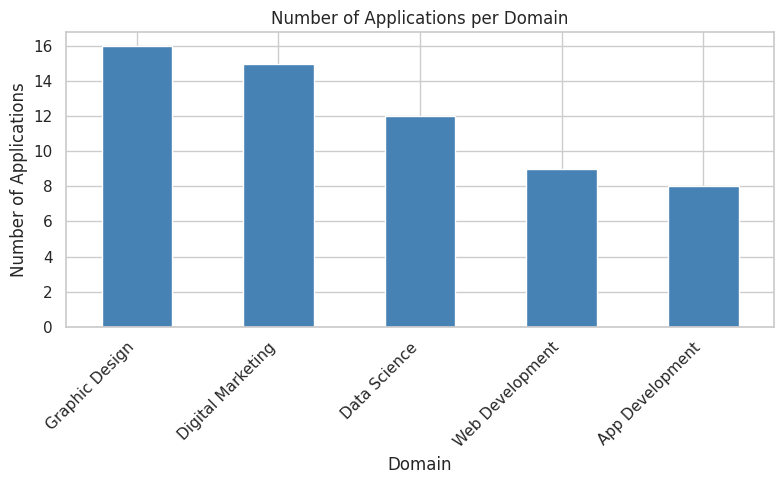

In [8]:
# Aggregation using value_counts()
domain_counts = df['Domain Applied'].value_counts()
print("Application Count per Domain:")
print(domain_counts)

# Visualization: Bar Chart
plt.figure(figsize=(8, 5))
domain_counts.plot(kind='bar', color='steelblue')
plt.title('Number of Applications per Domain')
plt.xlabel('Domain')
plt.ylabel('Number of Applications')
plt.xticks(rotation=45, ha='right')
plt.tight_layout()
plt.show()

# Markdown: Graphic Design attracted the highest number of applicants. Digital Marketing, Data Science, and Web Development followed closely behind, while App Development received comparatively fewer applications.


#2.How Did Applications Trend Over Time?

Monthly Application Volume:
Application Month
2026-08    10
2026-09     8
2026-10     3
Freq: M, dtype: int64


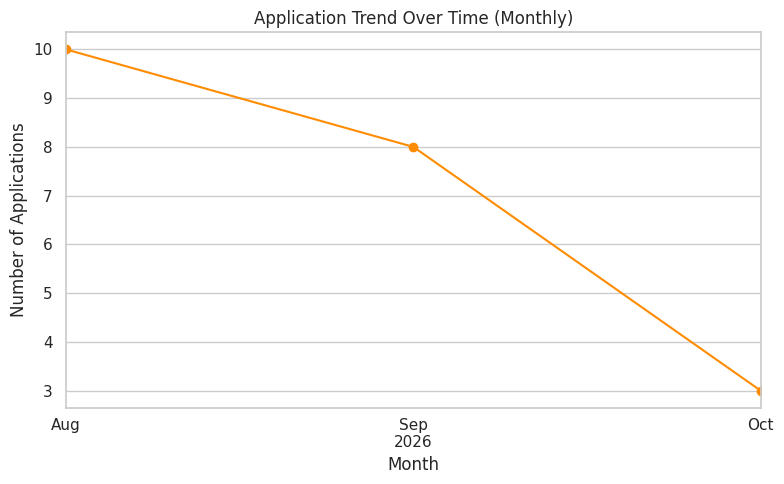

In [9]:
# Group by month using .dt.to_period('M')
df['Application Month'] = df['Application Date'].dt.to_period('M')
monthly_trend = df.groupby('Application Month').size()

print("Monthly Application Volume:")
print(monthly_trend)

# Visualization: Line Chart
plt.figure(figsize=(8, 5))
monthly_trend.plot(kind='line', marker='o', color='darkorange')
plt.title('Application Trend Over Time (Monthly)')
plt.xlabel('Month')
plt.ylabel('Number of Applications')
plt.tight_layout()
plt.show()

#Markdown :Applications reached their peak in August 2026, experienced another surge in September, and then gradually declined as October approached.


#3.What is the Acceptance Rate Overall & Per Domain?

Overall Status Counts:
Status
Under Review    34
Selected        23
Rejected        16
Name: count, dtype: int64

--- Status Count by Domain ---
Status             Rejected  Selected  Under Review
Domain Applied                                     
App Development           4         2             2
Data Science              2         5             5
Digital Marketing         3         5             7
Graphic Design            2         6             8
Web Development           1         2             6

--- Status Percentage (%) by Domain ---
Status             Rejected  Selected  Under Review
Domain Applied                                     
App Development        50.0      25.0          25.0
Data Science           16.7      41.7          41.7
Digital Marketing      20.0      33.3          46.7
Graphic Design         12.5      37.5          50.0
Web Development        11.1      22.2          66.7


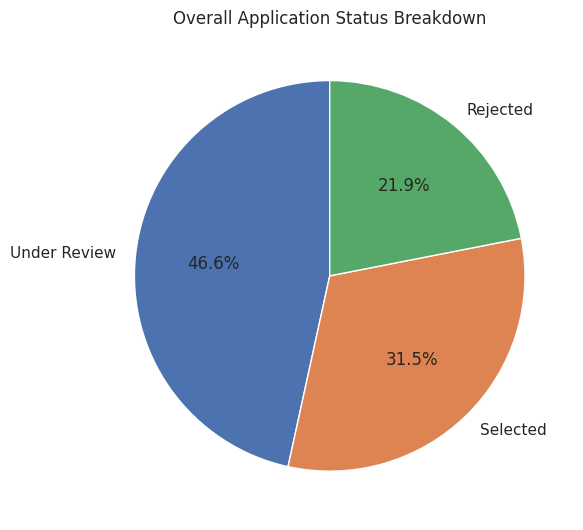

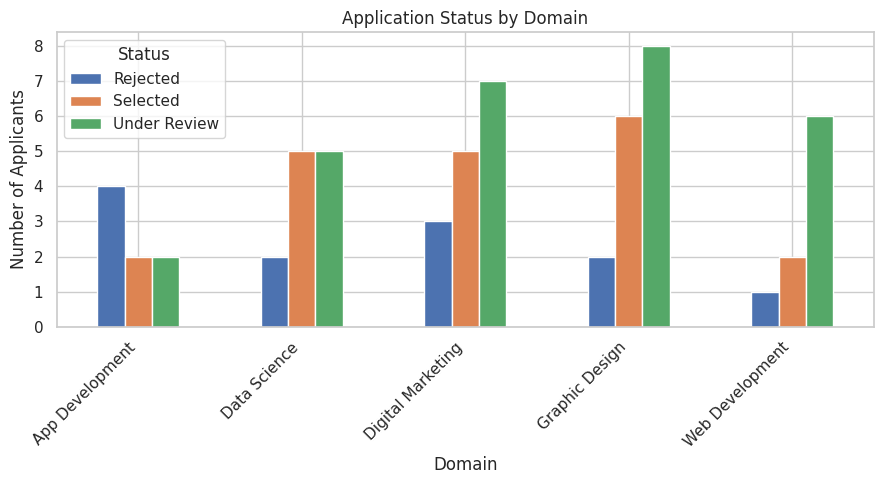

In [10]:
# Overall Status Breakdown
status_counts = df['Status'].value_counts()
print("Overall Status Counts:")
print(status_counts)

# Per-Domain Breakdown via pivot_table()
status_by_domain = pd.pivot_table(
    df,
    index='Domain Applied',
    columns='Status',
    values='Applicant Name',
    aggfunc='count',
    fill_value=0
)
print("\n--- Status Count by Domain ---")
print(status_by_domain)

# Percentage Breakdown
status_by_domain_pct = status_by_domain.div(status_by_domain.sum(axis=1), axis=0) * 100
print("\n--- Status Percentage (%) by Domain ---")
print(status_by_domain_pct.round(1))

# Visualization 1: Overall Status Pie Chart
plt.figure(figsize=(6, 6))
status_counts.plot(kind='pie', autopct='%1.1f%%', startangle=90)
plt.title('Overall Application Status Breakdown')
plt.ylabel('')
plt.tight_layout()
plt.show()

# Visualization 2: Grouped Bar Chart by Domain
status_by_domain.plot(kind='bar', figsize=(9, 5))
plt.title('Application Status by Domain')
plt.xlabel('Domain')
plt.ylabel('Number of Applicants')
plt.xticks(rotation=45, ha='right')
plt.legend(title='Status')
plt.tight_layout()
plt.show()

#Markdown: Graphic Design shows the highest acceptance rate compared to Data Science and Digital Marketing. In contrast, App Development and Web Development record the lowest acceptance rates.


#4.Which Universities Sent the Most Applicants?

Top 10 Universities:
University
Punjab University                                 17
COMSATS University                                13
The University of Faisalabad                      12
University of Sargodha                             9
University of Lahore                               9
Government College University Faisalabad           5
National University of Sciences and Technology     5
Not Specified                                      3
Name: count, dtype: int64


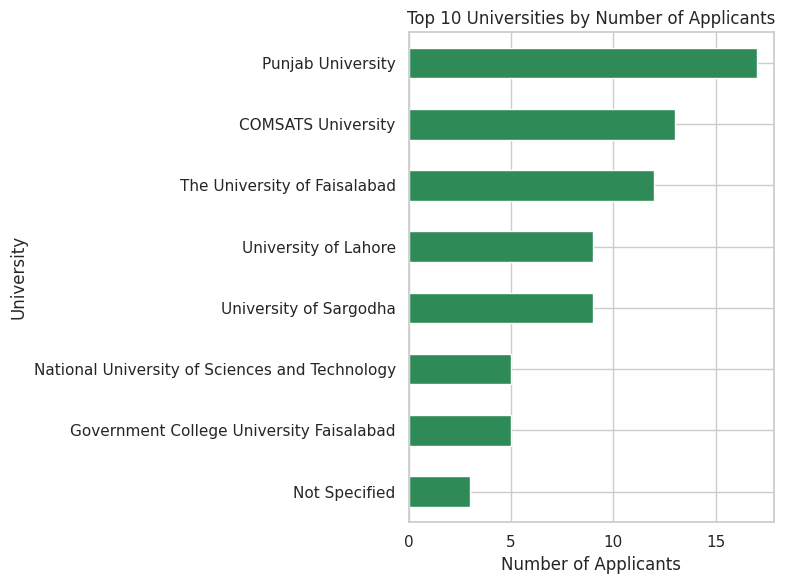

In [11]:
# Aggregation: Top 10 Universities
top_universities = df['University'].value_counts().head(10)
print("Top 10 Universities:")
print(top_universities)

# Visualization: Horizontal Bar Chart
plt.figure(figsize=(8, 6))
top_universities.sort_values().plot(kind='barh', color='seagreen')
plt.title('Top 10 Universities by Number of Applicants')
plt.xlabel('Number of Applicants')
plt.ylabel('University')
plt.tight_layout()
plt.show()

#Markdown: Punjab University produced the largest number of applicants, followed by The University of Faisalabad and COMSATS University.


#5. Bonus Chart (Application Distribution by Day of Week)

Applications by Day of Week:
Day of Week
Monday       5.0
Tuesday      0.0
Wednesday    2.0
Thursday     2.0
Friday       2.0
Saturday     3.0
Sunday       7.0
Name: count, dtype: float64


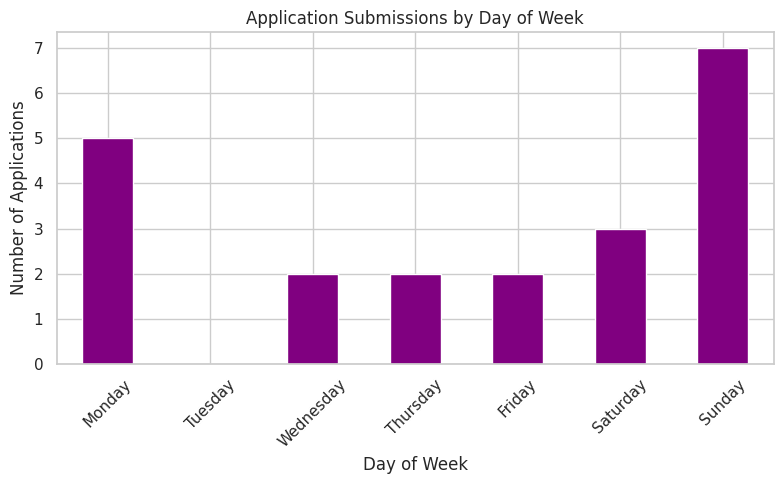

In [12]:
# Extract Day Name
df['Day of Week'] = df['Application Date'].dt.day_name()
days_order = ['Monday', 'Tuesday', 'Wednesday', 'Thursday', 'Friday', 'Saturday', 'Sunday']
day_counts = df['Day of Week'].value_counts().reindex(days_order).fillna(0)

print("Applications by Day of Week:")
print(day_counts)

# Visualization: Bar Chart
plt.figure(figsize=(8, 5))
day_counts.plot(kind='bar', color='purple')
plt.title('Application Submissions by Day of Week')
plt.xlabel('Day of Week')
plt.ylabel('Number of Applications')
plt.xticks(rotation=45)
plt.tight_layout()
plt.show()

#Markdown : Most applications were submitted during the weekend, with Sunday recording the highest activity.


## Key Insights
- Graphic Design stands out as the most popular domain, followed by Digital Marketing.  
- Application numbers peaked in August 2026, with another surge in September.  
- Acceptance rates vary across domains, with smaller fields often showing higher success percentages.  
- Punjab University, The University of Faisalabad, and COMSATS University are the leading sources of applicants.  
- The majority of applications were submitted on weekends, with Sundays showing the highest activity.  
